# W3 · From Separate Charts to a Visual System
**Business Intelligence · Individual work: Alessandro Lavezzi**
Data: C2 classification results of Group 01 (persistent overtime, fixed-term staff, six Santiago Metropolitan Health Services). All numbers are copied from the saved outputs of `GROUP_01_C1/notebooks/C2_classification.ipynb` (sections 3.2 and 4.1). No model is retrained here.

This notebook is the editable source of the three final views and of their three "before" versions. Run it top to bottom to regenerate `figures/`.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path

OUT = Path("figures"); OUT.mkdir(exist_ok=True)

# ---------------- DATA (C2 notebook, test set: 1,192 people, 204 persistent = 17.1%) ----------------
metrics = pd.DataFrame({            # section 4.1, test-set metrics
    "Reference rule":        {"Precision": 0.714, "Recall": 0.760, "F1": 0.736},
    "Logistic regression":   {"Precision": 0.664, "Recall": 0.833, "F1": 0.739},
}).T
cm = {                              # section 4.1, confusion matrices (rows: actual, cols: predicted)
    "Logistic regression (threshold 0.35)": np.array([[170, 34], [86, 902]]),   # [[TP, FN], [FP, TN]]
    "Reference rule":                       np.array([[155, 49], [62, 926]]),
}
odds = pd.Series({                  # section 3.2, odds ratios of the logistic regression
    "% of months with overtime (per SD)": 5.929,
    "Entitled to overtime (derecho_x)":   1.914,
    "Service: Norte":        1.368,
    "Service: Occidente":    1.324,
    "Service: SurOriente":   1.296,
    "Hours per month (per SD)": 1.183,
    "Staff: Directivo":      0.970,
    "Staff: Auxiliar":       0.980,
    "Staff: Médicos y afines": 0.821,
    "Months on payroll (per SD)": 0.789,
    "Service: Oriente":      0.736,
    "Staff: Técnico":        0.633,
    "Staff: Profesional":    0.626,
    "Service: Sur":          0.461,
})
numeric_feats = {"% of months with overtime (per SD)", "Entitled to overtime (derecho_x)",
                 "Hours per month (per SD)", "Months on payroll (per SD)"}
# sanity checks against the C2 notebook
assert cm["Logistic regression (threshold 0.35)"].sum() == 1192 and cm["Reference rule"].sum() == 1192
assert cm["Logistic regression (threshold 0.35)"][0].sum() == 204
print(metrics)

                     Precision  Recall     F1
Reference rule           0.714   0.760  0.736
Logistic regression      0.664   0.833  0.739


## Visual system (rules applied to all three views)
The same constants below drive every "after" chart, so a category keeps one visual meaning everywhere.

In [2]:
# ---------------- VISUAL SYSTEM ----------------
C_MODEL  = "#1F5FA8"   # blue  = the logistic regression (our model) in every view
C_REF    = "#8C8C8C"   # grey  = reference rule, neutral context and share ramps
C_ALERT  = "#D9822B"   # amber = highlight only: differences, errors, the dominant factor
C_INK    = "#222222"   # text
C_GRID   = "#DDDDDD"
HATCH_REF = "///"      # redundant, non-colour cue: reference = hatched

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": C_INK, "axes.labelcolor": C_INK,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130,
})
TITLE = dict(fontsize=14, fontweight="bold", loc="left")        # 1. action title (finding)
SUB   = dict(fontsize=10, color="#555555", loc="left")          # 2. subtitle: unit, period, n
NOTE  = dict(fontsize=8.5, color="#555555")                     # 3. source / reading note
CONTEXT = "Test set, 1,192 people (204 persistent), decision date 1 Sep 2025, predicting Sep 2025 - Aug 2026"

import textwrap
def heading(fig, title, subtitle, width_title=70, width_sub=105, top=0.97):
    t = textwrap.fill(title, width_title); sub = textwrap.fill(subtitle, width_sub)
    nt = t.count(chr(10)) + 1; ns = sub.count(chr(10)) + 1
    fig.text(0.01, top, t, fontsize=14, fontweight="bold", ha="left", va="top")
    fig.text(0.01, top - 0.055 * nt, sub, fontsize=9.5, color="#555555", ha="left", va="top")
    return top - 0.055 * nt - 0.04 * ns          # y where the plot area may start

def source(fig, text="Source: Group 01, C2 classification notebook (test set)."):
    fig.text(0.01, 0.005, text, **NOTE, ha="left", va="bottom")

## View 1 · Compare the model with the reference rule (test set)

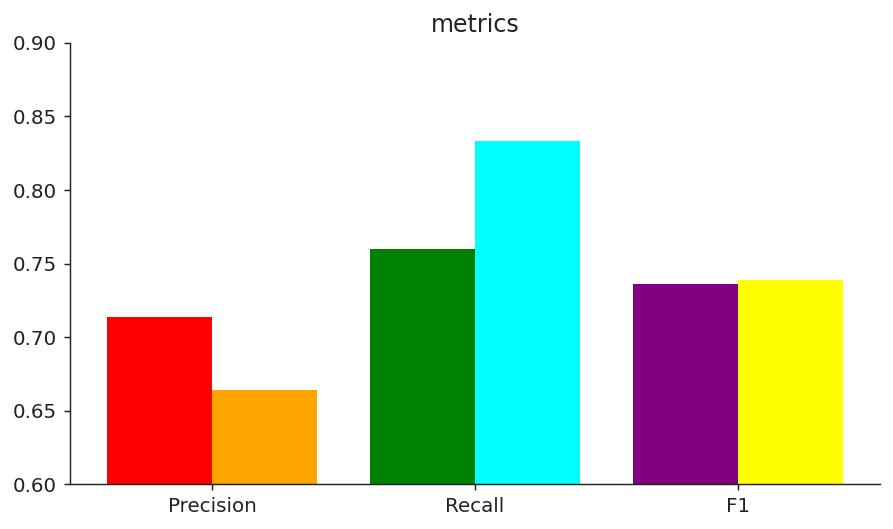

In [3]:
# ---------- BEFORE (same values) ----------
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(3)
ax.bar(x - 0.2, metrics.loc["Reference rule"], 0.4, color=["red", "green", "purple"])
ax.bar(x + 0.2, metrics.loc["Logistic regression"], 0.4, color=["orange", "cyan", "yellow"])
ax.set_xticks(x); ax.set_xticklabels(["Precision", "Recall", "F1"])
ax.set_ylim(0.6, 0.9)                       # truncated axis exaggerates gaps
ax.set_title("metrics")
fig.tight_layout(); fig.savefig(OUT / "view1_before.png"); plt.show()

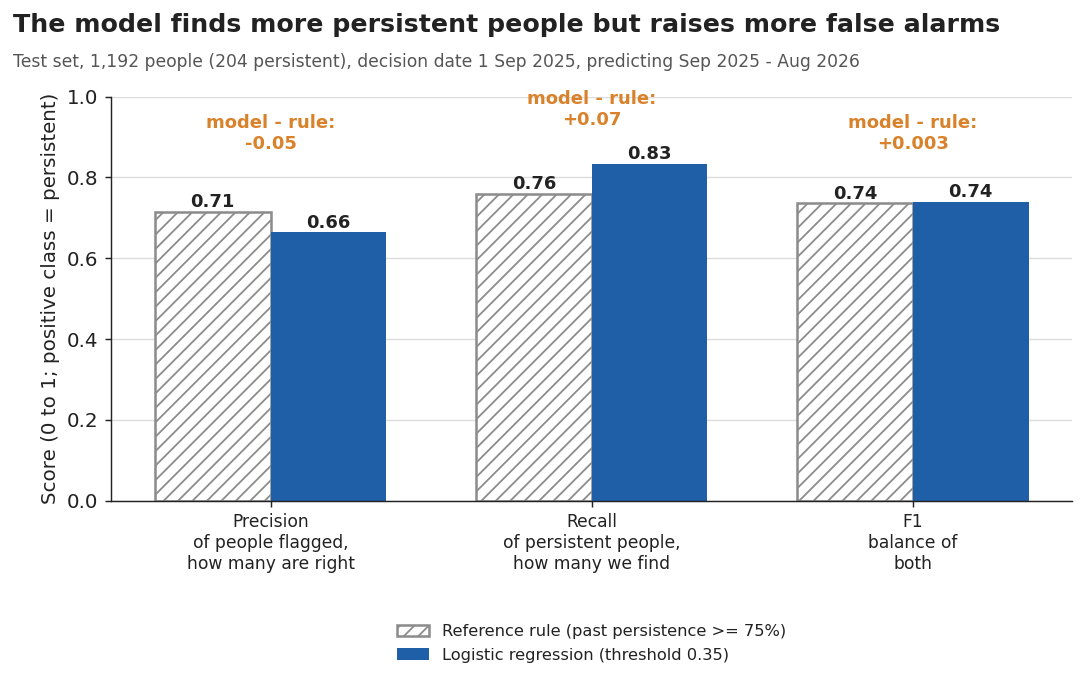

In [8]:
# ---------- AFTER ----------
fig, ax = plt.subplots(figsize=(8.4, 5.6))
labels = ["Precision\nof people flagged,\nhow many are right", "Recall\nof persistent people,\nhow many we find", "F1\nbalance of\nboth"]
x = np.arange(3); w = 0.36
ref = metrics.loc["Reference rule"].values; mod = metrics.loc["Logistic regression"].values
b1 = ax.bar(x - w/2, ref, w, color="white", edgecolor=C_REF, hatch=HATCH_REF, linewidth=1.4, label="Reference rule (past persistence >= 75%)")
b2 = ax.bar(x + w/2, mod, w, color=C_MODEL, label="Logistic regression (threshold 0.35)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.012, f"{r.get_height():.2f}", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 1); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.yaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylabel("Score (0 to 1; positive class = persistent)")
ax.text(0, 0.87, "model - rule:\n-0.05", ha="center", color=C_ALERT, fontweight="bold", fontsize=10)
ax.text(1, 0.93, "model - rule:\n+0.07", ha="center", color=C_ALERT, fontweight="bold", fontsize=10)
ax.text(2, 0.87, "model - rule:\n+0.003", ha="center", color=C_ALERT, fontweight="bold", fontsize=10)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=1, fontsize=9)
y0 = heading(fig, "The model finds more persistent people but raises more false alarms", CONTEXT)
fig.subplots_adjust(left=0.1, right=0.98, top=y0 - 0.02, bottom=0.30)
fig.savefig(OUT / "view1_after.png"); plt.show()

## View 2 · Summarize the errors of the model (confusion matrices)

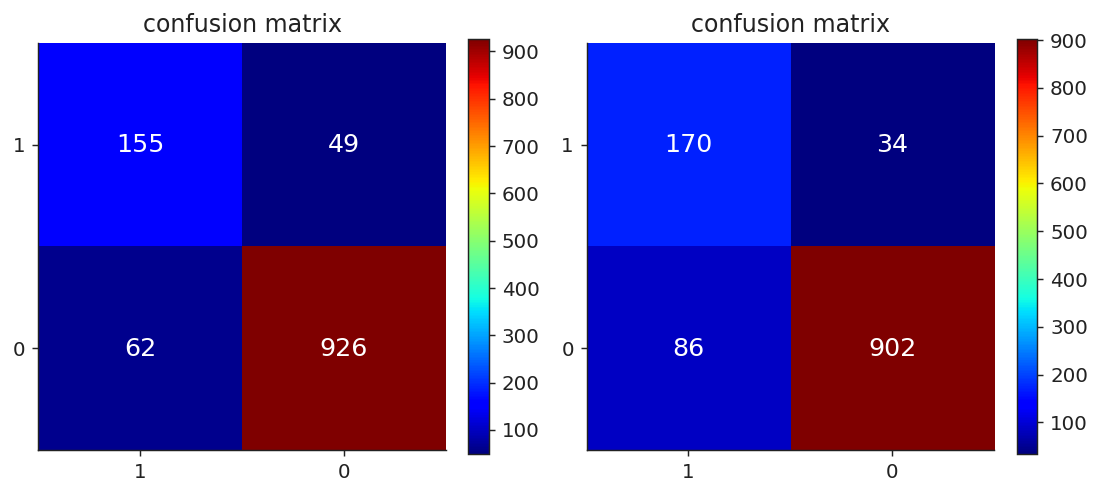

In [5]:
# ---------- BEFORE (same counts) ----------
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.0))
for ax, name in zip(axes, ["Reference rule", "Logistic regression (threshold 0.35)"]):
    m = cm[name]; im = ax.imshow(m, cmap="jet")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", color="white", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["1", "0"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["1", "0"])
    ax.set_title("confusion matrix"); fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(OUT / "view2_before.png"); plt.show()

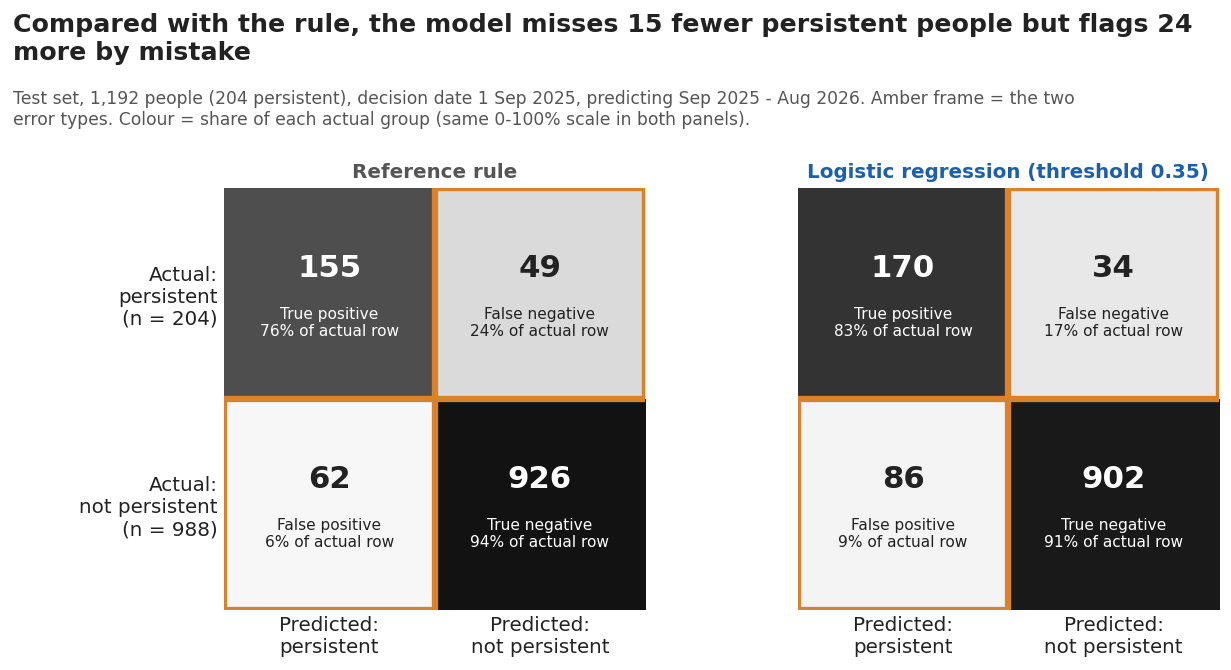

In [7]:
# ---------- AFTER ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharey=True)
names = ["Reference rule", "Logistic regression (threshold 0.35)"]
cell_names = [["True positive", "False negative"], ["False positive", "True negative"]]
cmap = plt.cm.Greys
for ax, name in zip(axes, names):
    m = cm[name]; share = m / m.sum(axis=1, keepdims=True)           # share of each ACTUAL group, same 0-100% scale in both panels
    ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            col = "white" if share[i, j] > 0.55 else C_INK
            ax.text(j, i - 0.12, f"{m[i, j]:,}", ha="center", va="center", fontsize=17, fontweight="bold", color=col)
            ax.text(j, i + 0.14, f"{cell_names[i][j]}\n{share[i, j]*100:.0f}% of actual row", ha="center", va="center", fontsize=8.5, color=col)
    for (i, j) in [(0, 1), (1, 0)]:                                   # highlight the two kinds of error with amber frame
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor=C_ALERT, linewidth=3.5))
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted:\npersistent", "Predicted:\nnot persistent"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual:\npersistent\n(n = 204)", "Actual:\nnot persistent\n(n = 988)"])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(name, fontsize=11, fontweight="bold", color=C_MODEL if "Logistic" in name else "#555555", pad=6)
y0 = heading(fig, "Compared with the rule, the model misses 15 fewer persistent people but flags 24 more by mistake",
             CONTEXT + ". Amber frame = the two error types. Colour = share of each actual group (same 0-100% scale in both panels).",
             width_title=80, width_sub=120)
fig.subplots_adjust(left=0.13, right=0.98, top=y0 - 0.06, bottom=0.12, wspace=0.08)
fig.savefig(OUT / "view2_after.png"); plt.show()

## View 3 · Identify the factors that raise or lower the odds of persistence

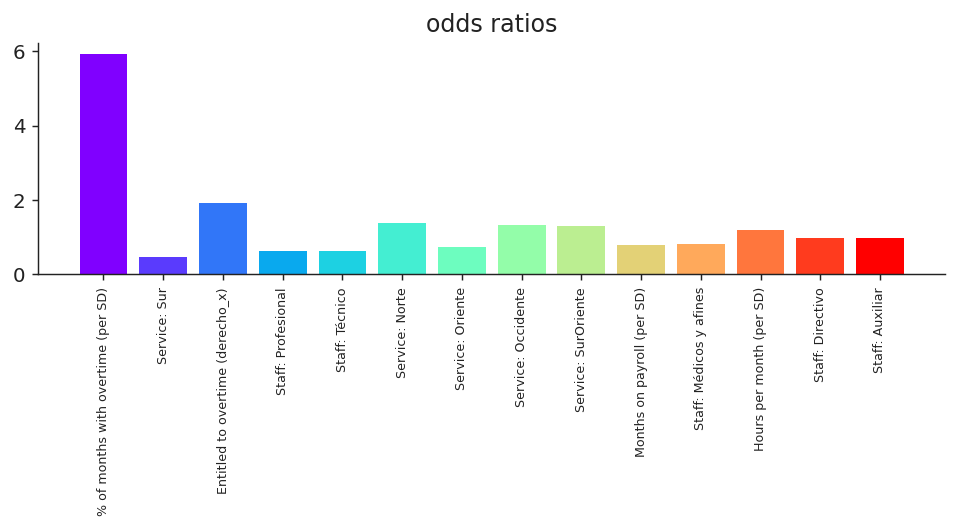

In [7]:
# ---------- BEFORE (same odds ratios, in the order of the C2 coefficient table = by size of the coefficient) ----------
c2_order = ["% of months with overtime (per SD)", "Service: Sur", "Entitled to overtime (derecho_x)", "Staff: Profesional", "Staff: Técnico",
            "Service: Norte", "Service: Oriente", "Service: Occidente", "Service: SurOriente", "Months on payroll (per SD)",
            "Staff: Médicos y afines", "Hours per month (per SD)", "Staff: Directivo", "Staff: Auxiliar"]
o = odds[c2_order]; assert len(o) == 14 and set(o.index) == set(odds.index)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(range(len(o)), o.values, color=plt.cm.rainbow(np.linspace(0, 1, len(o))))
ax.set_xticks(range(len(o))); ax.set_xticklabels(o.index, rotation=90, fontsize=7)
ax.set_title("odds ratios")
fig.tight_layout(); fig.savefig(OUT / "view3_before.png"); plt.show()

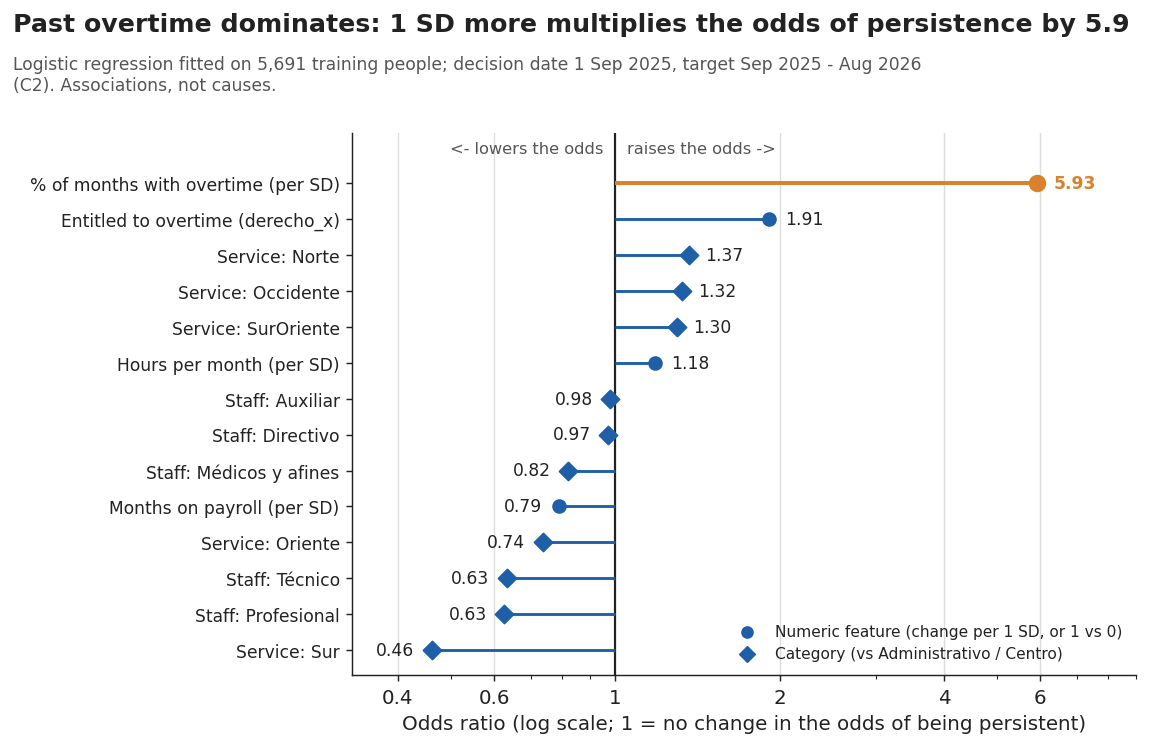

In [9]:
# ---------- AFTER ----------
s = odds.sort_values()                                  # ordered by value: top = strongest increase
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(s))
ax.set_xscale("log")
ax.axvline(1, color=C_INK, linewidth=1.2)               # odds ratio 1 = no association
for yi, (name, v) in zip(y, s.items()):
    top = name.startswith("% of months")
    color = C_ALERT if top else C_MODEL
    ax.hlines(yi, 1, v, color=color, linewidth=2.2 if top else 1.6)
    marker = "o" if name in numeric_feats else "D"      # shape = feature type (non-colour cue)
    ax.scatter(v, yi, s=75 if top else 50, color=color, marker=marker, zorder=3)
    ax.text(v * (1.07 if v >= 1 else 0.93), yi, f"{v:.2f}", va="center", ha="left" if v >= 1 else "right",
            fontsize=9.5, fontweight="bold" if top else "normal", color=C_ALERT if top else C_INK)
ax.set_yticks(y); ax.set_yticklabels(s.index, fontsize=9.5)
ax.set_xticks([0.4, 0.6, 1, 2, 4, 6]); ax.set_xticklabels(["0.4", "0.6", "1", "2", "4", "6"])
ax.set_xlim(0.33, 9)
ax.xaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xlabel("Odds ratio (log scale; 1 = no change in the odds of being persistent)")
ax.set_ylim(-0.7, len(s) + 0.4)
ax.text(0.95, len(s) - 0.15, "<- lowers the odds", fontsize=9, color="#555555", ha="right")
ax.text(1.05, len(s) - 0.15, "raises the odds ->", fontsize=9, color="#555555", ha="left")
ax.scatter([], [], marker="o", color=C_MODEL, label="Numeric feature (change per 1 SD, or 1 vs 0)")
ax.scatter([], [], marker="D", color=C_MODEL, label="Category (vs Administrativo / Centro)")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
y0 = heading(fig, "Past overtime dominates: 1 SD more multiplies the odds of persistence by 5.9",
             "Logistic regression fitted on 5,691 training people; decision date 1 Sep 2025, target Sep 2025 - Aug 2026 (C2). Associations, not causes.", width_title=90)
fig.subplots_adjust(left=0.30, right=0.97, top=y0 - 0.02, bottom=0.12)
fig.savefig(OUT / "view3_after.png"); plt.show()